# Program 07: the retrain baseline (the gold standard of unlearning)

**What:** train a model from scratch on all CIFAR-10 classes **except one** (class 3, "cat"). Save it as `results/retrain_model.pt`.

**How:** program 01's training recipe (ResNet-18, SGD, cosine learning rate, 30 epochs), with every cat image removed from the training data.

**Why:** exact unlearning means "behave as if never trained on that data". The retrained model **is** that ideal, and every unlearning method (programs 08, 09, and our own later) is judged by how close it gets to it.

**Understanding note:** retraining is perfect but too expensive to repeat on every deletion request. All approximate unlearning methods trade some of that perfection for speed.

**Done when:** cat accuracy is 0% (the class was never learned) and the other classes are near program 01.

## Phase C in short (for anyone reading this code for the first time)

Phases A and B were about **continual learning**: learning new tasks without forgetting old ones. Phase C switches to **unlearning**: forgetting something *on purpose*. We start simple, with one fully trained model on CIFAR-10 and one class to forget, before mixing unlearning with continual learning in Phase D.

Words used from here on:

| Term | Meaning |
|---|---|
| **forget set** | the data we are asked to remove: here, every cat image |
| **retain set** | everything else: the other 9 classes |
| **original model** | trained on all data, cats included (program 01) |
| **retrain model** | trained from scratch on the retain set only (this program) |
| **FA**, forget accuracy | accuracy on the forget set's test images. Retrain model: 0% |
| **RA**, retain accuracy | accuracy on the retain set's test images. Should stay high |
| **exact unlearning** | the result is identical to retraining without the data |
| **approximate unlearning** | cheaper methods that try to *look like* the retrain model (programs 08, 09) |

So this program builds the **target** that the next three programs aim for.

## 1. Setup
Same training settings as program 01, so the only difference between the two models is the missing class.

In [1]:
import gc, json, sys, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # lets us import common/

# Reload the shared code, so edits to common/ are picked up even without restarting the kernel.
import importlib
import common.utils, common.data, common.models, common.train
for module in (common.utils, common.data, common.models, common.train):
    importlib.reload(module)

import matplotlib.pyplot as plt
import numpy as np
import torch

from common.data import get_cifar10_unlearning_loaders
from common.models import resnet18_cifar
from common.train import evaluate, per_class_accuracy, predict_all, train_one_epoch
from common.utils import RESULTS_DIR, get_device, log_run, set_seed

SETTINGS = {
    "forget_class": 3,       # CIFAR-10 class 3 = cat
    "epochs": 30, "lr": 0.1, "batch_size": 128, "weight_decay": 5e-4,
    "seed": 0, "workers": 2,  # data-loading processes for training (each uses a few hundred MB of RAM)
    "force_retrain": False,   # False: if results/retrain_model.pt already exists, skip training
}
set_seed(SETTINGS["seed"])
device = get_device()
print("device:", device)

device: cuda


## 2. Data: split CIFAR-10 into forget and retain sets

`get_cifar10_unlearning_loaders` (in `common/data.py`) does the split once; programs 08 to 10 reuse it. The first run downloads CIFAR-10 (about 170 MB) into `data/`.

We expect 45,000 retain + 5,000 forget training images, and 9,000 + 1,000 test images.

In [2]:
loaders = get_cifar10_unlearning_loaders(SETTINGS["forget_class"], SETTINGS["batch_size"], SETTINGS["workers"])
classes = loaders["classes"]
FORGET = SETTINGS["forget_class"]

for name in ["train_retain", "train_forget", "test_retain", "test_forget"]:
    print(f"{name:13} {len(loaders[name].dataset):6} images")
print(f"\nforget class: {FORGET} ({classes[FORGET]})")

# Check: no cat in the retain set (read the stored labels, no image loading).
retain_sub = loaders["train_retain"].dataset
assert all(retain_sub.dataset.targets[i] != FORGET for i in retain_sub.indices), "a cat leaked into the retain set"
print("retain set has no cat images: OK")

train_retain   45000 images
train_forget    5000 images
test_retain     9000 images
test_forget     1000 images

forget class: 3 (cat)
retain set has no cat images: OK


## 3. The model: still 10 outputs

The model keeps **all 10 outputs**, including one for cat, even though it never sees a cat. Two reasons:
- It must be directly comparable with the original model: same architecture, same output meaning, so later programs can compare them output by output.
- An unlearned model in practice still has the cat output; unlearning doesn't change the architecture.

The cat output is never the correct answer during training, so cross-entropy only ever pushes it **down**. That is why we expect cat accuracy to be exactly 0%.

In [3]:
model = resnet18_cifar(num_classes=10).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=SETTINGS["lr"], momentum=0.9,
                            weight_decay=SETTINGS["weight_decay"])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=SETTINGS["epochs"])
scaler = torch.amp.GradScaler(enabled=device.type == "cuda")

## 4. Train on the retain set only

Program 01's loop, using only `train_retain`. After each epoch we measure:
- **RA**: accuracy on the 9,000 retain test images (should climb to program 01's level).
- **FA**: accuracy on the 1,000 cat test images (should stay at 0%).

About 20 to 30 seconds per epoch on the laptop GPU, so roughly 12 to 15 minutes in total.

**Already trained?** If `results/retrain_model.pt` exists, this section skips training and the rest of the notebook uses the saved model. Set `force_retrain` to True in section 1 to train again. The per-epoch history is saved to `results/07_history.json`, so section 8 can draw the curves later without retraining.

In [4]:
model_path = RESULTS_DIR / "retrain_model.pt"
history_path = RESULTS_DIR / "07_history.json"

if model_path.exists() and not SETTINGS["force_retrain"]:
    print(f"{model_path.name} already exists: skipping training (set force_retrain=True to train again).")
else:
    history = {"train_loss": [], "train_acc": [], "ra": [], "fa": []}
    start = time.time()
    for epoch in range(1, SETTINGS["epochs"] + 1):
        loss, train_acc = train_one_epoch(model, loaders["train_retain"], optimizer, scaler, device)
        ra = evaluate(model, loaders["test_retain"], device)
        fa = evaluate(model, loaders["test_forget"], device)
        scheduler.step()
        for k, v in zip(history, [loss, train_acc, ra, fa]):
            history[k].append(v)
        print(f"epoch {epoch:2d}/{SETTINGS['epochs']}  loss {loss:.3f}  train {train_acc*100:5.1f}%  "
              f"RA {ra*100:5.1f}%  FA {fa*100:4.1f}%  ({time.time()-start:.0f}s)")
    train_minutes = (time.time() - start) / 60

    RESULTS_DIR.mkdir(exist_ok=True)
    torch.save(model.state_dict(), model_path)
    history_path.write_text(json.dumps({"history": history, "minutes": train_minutes}))
    print(f"saved model to {model_path} and history to {history_path}")

retrain_model.pt already exists: skipping training (set force_retrain=True to train again).


## 5. Free memory, then test one model at a time

The laptop has 8 GB of RAM, so from here on we keep as little in memory as possible:
1. Shut down the training loaders' worker processes and delete the training model and optimizer.
2. `test_model` loads **one** saved model, measures everything we need, keeps only the numbers, and deletes the model before returning.

All comparisons and plots below use those saved numbers, never two models at once.

The first check: reload the retrain model from disk and confirm its accuracy matches the end of training.

In [5]:
# 1. Free what training used.
loaders["train_retain"] = loaders["train_forget"] = None     # their worker processes shut down
for name in ["model", "optimizer", "scheduler", "scaler"]:
    globals().pop(name, None)
gc.collect()
torch.cuda.empty_cache()

# 2. Test one saved model, keep only numbers.
def test_model(path):
    m = resnet18_cifar(num_classes=10).to(device)
    m.load_state_dict(torch.load(path, map_location=device))
    acc = per_class_accuracy(m, loaders["test_all"], device)
    probs_forget, _ = predict_all(m, loaders["test_forget"], device)
    probs_retain, _ = predict_all(m, loaders["test_retain"], device)
    out = {"per_class_acc": acc,
           "forget_probs": probs_forget.numpy(),
           "retain_conf": probs_retain.max(1).values.numpy()}
    del m, probs_forget, probs_retain
    gc.collect()
    torch.cuda.empty_cache()
    return out

retrain = test_model(model_path)
retain_mask = np.arange(10) != FORGET
ra_re, fa_re = retrain["per_class_acc"][retain_mask].mean(), retrain["per_class_acc"][FORGET]
print(f"reloaded retrain model: RA {ra_re*100:.2f}%  FA {fa_re*100:.2f}%")

if history_path.exists():
    saved = json.loads(history_path.read_text())
    history, train_minutes = saved["history"], saved["minutes"]
    # RA here is the mean of per-class accuracies; with 1,000 test images per class it equals overall RA.
    same = abs(ra_re - history["ra"][-1]) < 1e-6 and abs(fa_re - history["fa"][-1]) < 1e-6
    print(f"end of training:        RA {history['ra'][-1]*100:.2f}%  FA {history['fa'][-1]*100:.2f}%  "
          f"({'same' if same else 'DIFFERENT, check this'})")
else:
    history, train_minutes = None, None
    print("no saved training history (the model was trained before history saving was added); "
          "compare with the last epoch printed in section 4.")

reloaded retrain model: RA 94.94%  FA 0.00%
no saved training history (the model was trained before history saving was added); compare with the last epoch printed in section 4.


## 6. Per-class accuracy: retrain model vs original model

The "Done when" check: cat at 0%, the other 9 classes close to program 01.

The original model comes from program 01 (`results/01_resnet18_cifar10.pt`). It is tested with the same `test_model` function, after the retrain model is already gone from memory. If the file is missing, this cell shows the retrain model only.

       class   retrain  original
    airplane     94.7%     94.1%
  automobile     96.6%     97.8%
        bird     92.0%     91.0%
         cat      0.0%     85.7%  <- forget class
        deer     94.7%     94.7%
         dog     93.0%     89.9%
        frog     96.0%     95.9%
       horse     95.9%     95.0%
        ship     96.1%     96.2%
       truck     95.5%     96.0%

retrain model:  RA 94.9%  FA 0.0%
original model: RA 94.5%  FA 85.7%


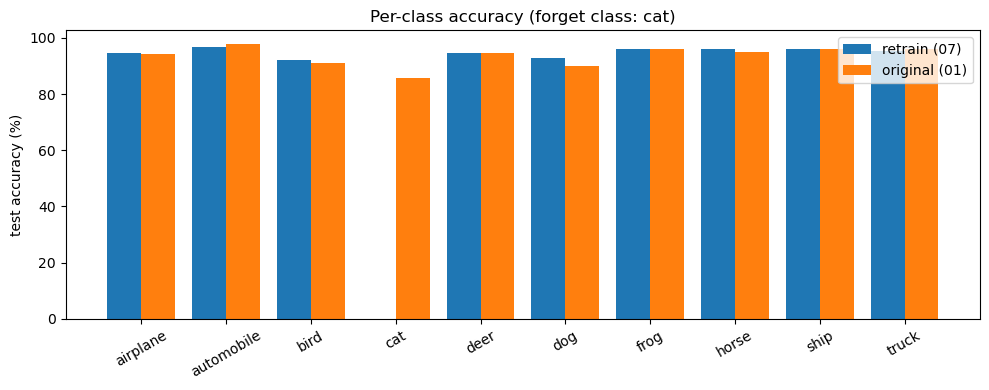

In [6]:
original_path = RESULTS_DIR / "01_resnet18_cifar10.pt"
original = test_model(original_path) if original_path.exists() else None
if original is None:
    print(f"{original_path.name} not found: showing the retrain model only. Run program 01 to create it.\n")

acc_retrain = retrain["per_class_acc"]
acc_original = original["per_class_acc"] if original is not None else None

print(f"{'class':>12} {'retrain':>9}" + (f" {'original':>9}" if acc_original is not None else ""))
for c in range(10):
    mark = "  <- forget class" if c == FORGET else ""
    row = f"{classes[c]:>12} {acc_retrain[c]*100:8.1f}%"
    if acc_original is not None:
        row += f" {acc_original[c]*100:8.1f}%"
    print(row + mark)

print(f"\nretrain model:  RA {acc_retrain[retain_mask].mean()*100:.1f}%  FA {acc_retrain[FORGET]*100:.1f}%")
if acc_original is not None:
    print(f"original model: RA {acc_original[retain_mask].mean()*100:.1f}%  FA {acc_original[FORGET]*100:.1f}%")

x = np.arange(10)
width = 0.4
plt.figure(figsize=(10, 4))
plt.bar(x - width / 2 if acc_original is not None else x, acc_retrain * 100, width, label="retrain (07)")
if acc_original is not None:
    plt.bar(x + width / 2, acc_original * 100, width, label="original (01)")
plt.xticks(x, classes, rotation=30)
plt.ylabel("test accuracy (%)")
plt.title(f"Per-class accuracy (forget class: {classes[FORGET]})")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "07_per_class.png", dpi=120)
plt.show()

## 7. What does the ideal model do with a cat image?

FA = 0% only says the retrain model never answers "cat". It doesn't say what it answers instead. That matters a lot for the next programs: a good unlearning method should make the original model behave **like this**, not just "never say cat".

We look at two things on the 1,000 cat test images:
1. **Which class it predicts.** We expect mostly visually similar animals (dog, then maybe deer, frog, bird), not a uniform spread. A model that never saw cats still sees "a furry four-legged animal".
2. **How confident it is.** On classes it was trained on, a well-trained model is usually very confident. On cats, which it never saw, we expect lower confidence. This difference is exactly what program 10's membership inference attack looks for: if an unlearned model is still *very* confident on cats, it probably still remembers them.

retrain model on cat test images, predicted as:
           dog:  58.2%
          frog:  13.4%
          bird:   9.9%
          deer:   7.5%
         horse:   5.3%
      airplane:   2.3%
         truck:   1.5%
          ship:   1.3%
    automobile:   0.6%

average top-class confidence: retain test images 97.3%, cat test images 83.6%
average probability given to 'cat' on cat images: 0.012%
(original model, for comparison: 85.7% of cat images called 'cat', confidence on cat images 91.8%)


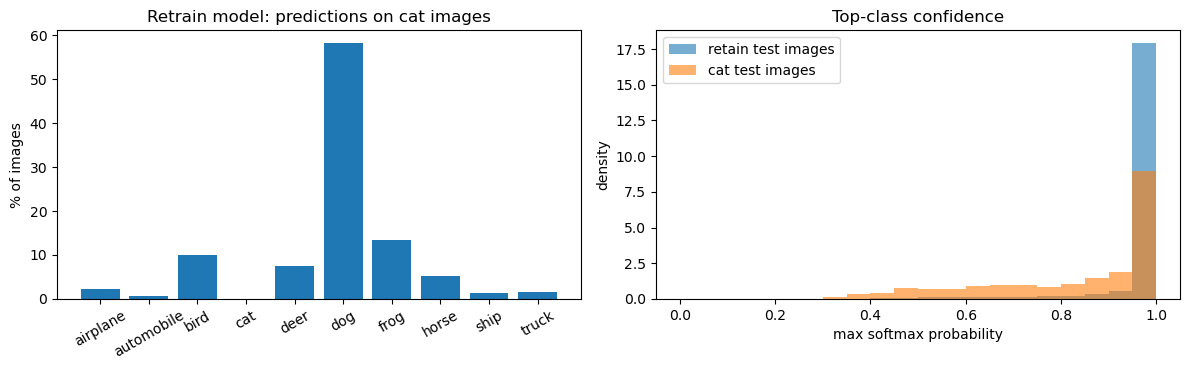

In [7]:
probs_forget = retrain["forget_probs"]
pred = probs_forget.argmax(1)
share = np.bincount(pred, minlength=10) / len(pred)
print(f"retrain model on {classes[FORGET]} test images, predicted as:")
for c in np.argsort(-share):
    if share[c] > 0:
        print(f"  {classes[c]:>12}: {share[c]*100:5.1f}%")

conf_forget = probs_forget.max(1)
conf_retain = retrain["retain_conf"]
print(f"\naverage top-class confidence: retain test images {conf_retain.mean()*100:.1f}%, "
      f"{classes[FORGET]} test images {conf_forget.mean()*100:.1f}%")
print(f"average probability given to '{classes[FORGET]}' on {classes[FORGET]} images: "
      f"{probs_forget[:, FORGET].mean()*100:.3f}%")
if original is not None:
    o_share = np.bincount(original["forget_probs"].argmax(1), minlength=10) / len(pred)
    print(f"(original model, for comparison: {o_share[FORGET]*100:.1f}% of cat images called '{classes[FORGET]}', "
          f"confidence on cat images {original['forget_probs'].max(1).mean()*100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(classes, share * 100)
axes[0].set(title=f"Retrain model: predictions on {classes[FORGET]} images", ylabel="% of images")
axes[0].tick_params(axis="x", rotation=30)
bins = np.linspace(0, 1, 21)
axes[1].hist(conf_retain, bins=bins, alpha=0.6, density=True, label="retain test images")
axes[1].hist(conf_forget, bins=bins, alpha=0.6, density=True, label=f"{classes[FORGET]} test images")
axes[1].set(title="Top-class confidence", xlabel="max softmax probability", ylabel="density")
axes[1].legend()
fig.tight_layout()
plt.show()

# Saved for programs 08-10: the target prediction pattern on cat images.
np.savez(RESULTS_DIR / "07_retrain_reference.npz", per_class_acc=acc_retrain,
         forget_pred_share=share, forget_conf=conf_forget, retain_conf=conf_retain)

## 8. Training curves

In [8]:
if history is None:
    print("no saved history: see the per-epoch numbers printed in section 4.")
else:
    ep = range(1, len(history["ra"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    ax1.plot(ep, history["train_loss"])
    ax1.set(title="Training loss (retain set)", xlabel="epoch", ylabel="cross-entropy")
    ax2.plot(ep, [a * 100 for a in history["ra"]], label="RA (retain test)")
    ax2.plot(ep, [a * 100 for a in history["fa"]], label=f"FA ({classes[FORGET]} test)")
    ax2.set(title="Retain vs forget accuracy", xlabel="epoch", ylabel="accuracy (%)", ylim=(-2, 100))
    ax2.legend()
    fig.tight_layout()
    plt.savefig(RESULTS_DIR / "07_curves.png", dpi=120)
    plt.show()

no saved history: see the per-epoch numbers printed in section 4.


## 9. How expensive was this?

Retraining is the gold standard, but its cost is the whole point of the understanding note. Here we write it down so programs 08 and 09 can compare: they will take seconds to a minute, against the minutes of full training below. On a real model (ImageNet-scale, or a large language model) the same retraining would take days or weeks, for *every* deletion request.

In [9]:
if train_minutes is not None:
    print(f"retraining took {train_minutes:.1f} minutes for {SETTINGS['epochs']} epochs on 45,000 images")
else:
    print("training time not saved: it is the last (…s) value printed in section 4.")

training time not saved: it is the last (…s) value printed in section 4.


## 10. Log the run

In [10]:
log_run("07_retrain_baseline", SETTINGS,
        {"ra": float(acc_retrain[retain_mask].mean()), "fa": float(acc_retrain[FORGET]),
         "per_class_acc": [round(float(a), 4) for a in acc_retrain],
         "forget_pred_share": [round(float(s), 4) for s in share],
         "conf_retain": float(conf_retain.mean()), "conf_forget": float(conf_forget.mean()),
         "minutes": round(train_minutes, 1) if train_minutes is not None else None})
print("logged to", RESULTS_DIR / "runs.jsonl")

logged to /run/media/adarsh/AAE039EFE039C1FD/std/research/results/runs.jsonl


## Lab notebook

*Write one paragraph here: what you saw, and what surprised you.*

Questions to answer in it:
1. Is cat accuracy exactly 0%? Why is that guaranteed, and not just likely?
2. Did removing cats change the *other* classes? Look especially at dog: is it higher or lower than in the original model, and why? (Hint: in the original model, some dogs were mistaken for cats.)
3. What does the retrain model predict for cat images? Why is that pattern, and not "random class", the right target for an unlearning method?
4. Retrain confidence on cat images vs retain images: how big is the gap? How could an attacker use a gap like that to tell whether a model was trained on cats? (This is program 10.)
5. How long did retraining take? How often could you afford it if deletion requests arrived every hour?